# First Classification 🐥🐥

0. Import the usual libraries.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import  OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore", category=FutureWarning) # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"


1. The file `data/exam_scores.txt` contains the scores of 100 applicants in two exams, and whether they were admitted (1) or not (0). Load it into a DataFrame.

Pay attention to the header of the DataFrame: there's something annoying about it! Look at the documentation of `pd.read_csv()` to find a way to solve the problem 🤓

In [ ]:
data = pd.read_csv('data/exam_scores.txt', 
                   header=None)
print("Shape of dataset: ", data.shape)
data.head()

Shape of dataset:  (100, 3)


,0,1,2
0,73.756683,97.700376,1
1,92.804966,76.043251,1
2,84.297998,59.975417,1
3,45.764503,66.661808,0
4,51.011640,91.096645,1


2. Rename the columns with the following names:

"Col_1" / "Col_2" / "Target"

In [ ]:
col_names = {
    0: "Col_1",
    1: "Col_2",
    2: "Target"
}

data = data.rename(columns= col_names)

data.head()

,Col_1,Col_2,Target
0,73.756683,97.700376,1
1,92.804966,76.043251,1
2,84.297998,59.975417,1
3,45.764503,66.661808,0
4,51.011640,91.096645,1


3. Visualize the data as a scatter plot, with a different color for each class.

In [ ]:
fig = px.scatter(data, x = 'Col_1', y = 'Col_2', color = data['Target'].astype('str'), labels = {'color': 'Target'})
fig.show()

4. Separate X and y into two different objects.

In [ ]:
# Separate target variable Y from features X
print("Separating labels from features...")
target_variable = "Target"

X = data.drop(target_variable, axis = 1)
Y = data.loc[:,target_variable]

print("...Done.")
print()

print('Y : ')
print(Y.head())
print()
print('X :')
print(X.head())

Separating labels from features...
...Done.

Y : 
0    1
1    1
2    1
3    0
4    1
Name: Target, dtype: int64

X :
       Col_1      Col_2
0  73.756683  97.700376
1  92.804966  76.043251
2  84.297998  59.975417
3  45.764503  66.661808
4  51.011640  91.096645


5. Split the data into a train set and a test set.

In [ ]:
## Statify splitting when you're training a classification model !
X_train, X_test, Y_train, Y_test = train_test_split(X ,Y ,test_size = 0.2, stratify = Y, random_state = 42)

6. Do you think that the two variables "Col_1" and "Col_2" would be good predictors of the target?

In [ ]:
# Univariate analysis
# Distribution of each numeric variable
num_features = ['Col_1', 'Col_2']
for f in num_features:
    fig = px.histogram(data, f, color = 'Target', facet_row = 'Target', histnorm = 'probability')
    fig.show()

The distributions of "Col_1" and "Col_2" seem quite different depending on the value of the target variable. So we can be quite confident that these features will be useful to predict the value of _Target_ 🤞

7. Analyze the explanatory variables: what preprocessing is necessary? Apply it.

In [ ]:
data.describe(include = 'all')

,Col_1,Col_2,Target
count,100.000000,100.000000,100.000000
mean,63.871697,66.541336,0.560000
std,20.331975,20.633825,0.498888
min,30.261397,30.362521,0.000000
25%,46.514310,48.678494,0.000000
50%,65.049759,66.646549,1.000000
75%,79.312678,84.053402,1.000000
max,99.685020,98.627633,1.000000


Some good news:
* There are no missing values in this dataset --> no imputation needed
* Although this is a classification problem, the _Target_ is already encoded as 0s and 1s, so we don't need the LabelEncoder
* All the features (_Col_1_ and _Col_2_) are numeric, so we just need to apply a StandardScaler to the whole array X

In [ ]:
# Data must be normalized to guarantee that we can interpret the model's parameters
print("Performing preprocessings on train set...")
print(X_train.head())
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
print('...Done.')
print(X_train[0:5]) # MUST use this syntax because X_train is a numpy array and not a pandas DataFrame anymore
print()

# Preprocessings on test set
print("Performing preprocessings on test set...")
print(X_test.head()) 
X_test = scaler.transform(X_test) ### NO fit on X_test
print('...Done.')
print(X_test[0:5,:]) # MUST use this syntax because X_test is a numpy array and not a pandas DataFrame anymore
print()

Performing preprocessings on train set...
        Col_1      Col_2
39  40.812276  92.757837
72  91.185392  74.465833
49  90.993756  96.565674
70  77.023561  62.608802
5   91.148741  54.094747
...Done.
[[-1.10733947  1.18291842]
 [ 1.32110695  0.32763857]
 [ 1.31186834  1.36096158]
 [ 0.63837675 -0.22676103]
 [ 1.31934004 -0.62485298]]

Performing preprocessings on test set...
        Col_1      Col_2
34  78.442248  96.642764
10  51.212270  83.567317
75  89.155202  58.806178
18  73.552546  59.323256
23  33.075941  65.910251
...Done.
[[ 0.70677048  1.36456608]
 [-0.60596432  0.75319696]
 [ 1.22323317 -0.40456044]
 [ 0.47104198 -0.38038341]
 [-1.4803018  -0.07239506]]



8. Use the LogisticRegression class from sklearn to create a model instance and train it.

In [ ]:
classifier = LogisticRegression()
classifier.fit(X_train, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

9. What's the accuracy on the train set? And on the test set?

Find a way to evaluate the scores without explicitly computing the model's predictions.

In [ ]:
# The method .score() from LogisticRegression() returns the accuracy!
print('Train accuracy : {}\nTest accuracy : {}'.format(classifier.score(X_train, Y_train), classifier.score(X_test, Y_test)))

Train accuracy : 0.8625
Test accuracy : 0.95


10. What's the average score with a cross-validation using K=10? What's the standard deviation of the score?

In [ ]:
scores = cross_val_score(classifier,X_train, Y_train, cv=10)
avg = scores.mean()
std = scores.std()
print('Cross-validated accuracy : {}\nstandard deviation : {}'.format(avg, std))

Cross-validated accuracy : 0.8625
standard deviation : 0.10383279828647594


11. Is the model underfitting/overfitting?

The test accuracy seems a bit higher than the train accuracy, which is unusual (it's as if a student who had not learned their lesson miraculously got very good results in the final exam 😇)...
This is neither underfitting nor overfitting 🤔

Actually, the cross-validation shows that the score can typically vary by $\pm 0.10$ just by switching some examples between the train and test sets. We can conclude that there's **no significant difference** between the train score and the test score! The model has a good balance between bias and variance, which is good news!

12. Create objects containing the model's predictions on the train/test sets, as well as the estimated probabilities.

In [ ]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = classifier.predict(X_train)
print("...Done.")
print(Y_train_pred[:5])
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on training set...")
Y_train_proba = classifier.predict_proba(X_train)
print("...Done.")
print(Y_train_proba[:5])
print()

Predictions on training set...
...Done.
[1 1 1 1 1]

Probabilities on training set...
...Done.
[[0.35274991 0.64725009]
 [0.03666192 0.96333808]
 [0.00705802 0.99294198]
 [0.22831628 0.77168372]
 [0.15383053 0.84616947]]



In [ ]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = classifier.predict(X_test)
print("...Done.")
print(Y_test_pred[:5])
print()

# It's also possible to get the probabilities estimated by the model:
print("Probabilities on test set...")
Y_test_proba = classifier.predict_proba(X_test)
print("...Done.")
print(Y_test_proba[:5])
print()

Predictions on test set...
...Done.
[1 1 1 1 0]

Probabilities on test set...
...Done.
[[0.01907766 0.98092234]
 [0.32263604 0.67736396]
 [0.12953734 0.87046266]
 [0.33489645 0.66510355]
 [0.88836363 0.11163637]]



13. Display the confusion matrix of your model's predictions on the training data, then do the same on the test data. What do you think of your model's performance? Do you think it would generalize well to unseen data?

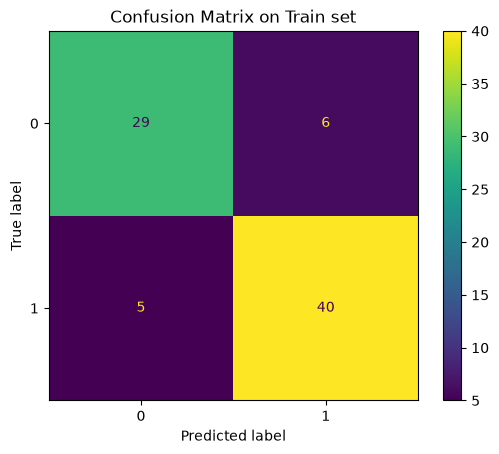

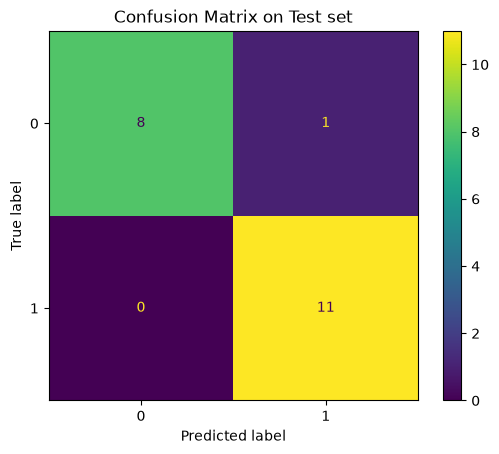

In [ ]:
# Visualize confusion matrices
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Train set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(classifier, X_train, Y_train, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="Confusion Matrix on Test set") # Set a title that we will add into ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(classifier, X_test, Y_test, ax=ax) # ConfusionMatrixDisplay from sklearn
plt.show()

**From the questions above, we can deduce that the generalization performance is very good! Indeed, the test accuracy is comparable to the train accuracy, and the confusion matrix shows that prediction errors are few 🥳🥳**

14. Plot the ROC curve for the train set and the test set.

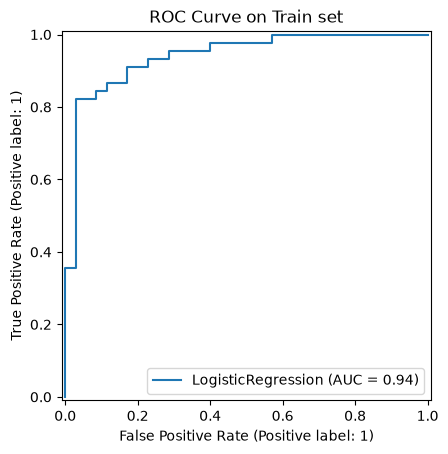

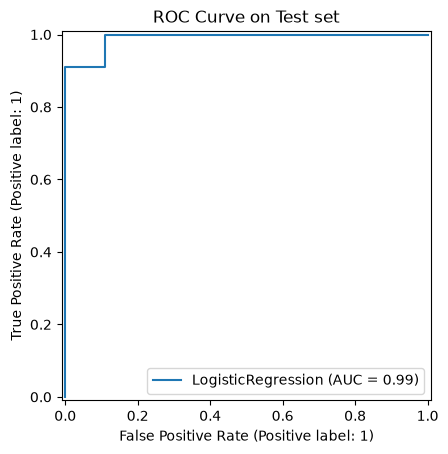

In [ ]:
# Visualize ROC curves
_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Train set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(classifier, X_train, Y_train, ax=ax) # RocCurveDisplay from sklearn
plt.show()

_ , ax = plt.subplots() # Get subplot from matplotlib
ax.set(title="ROC Curve on Test set") # Set a title that we will add into ConfusionMatrixDisplay
RocCurveDisplay.from_estimator(classifier, X_test, Y_test, ax=ax) # RocCurveDisplay from sklearn
plt.show()

**The area under the curves is quite close to 1. This means that the model is robust: it separates the two classes well, whatever the classification threshold.**

15. Create a DataFrame named predictions_df_train that contains the following values on the train set:
* explanatory variables "Col_1" and "Col_2"
* the target variable Y
* the predictions Y_pred 
* the probabilities estimated by the classifier.

Sort the rows by probability (in ascending order).

In [ ]:
predictions_df_train = pd.DataFrame(X_train, columns = ['Col_1', 'Col_2'])
predictions_df_train["Y"] = Y_train.tolist()
predictions_df_train["Y_pred"] = Y_train_pred.tolist()
predictions_df_train["Proba"] = Y_train_proba[:,1]
predictions_df_train = predictions_df_train.sort_values(by="Proba")
predictions_df_train.head()

,Col_1,Col_2,Y,Y_pred,Proba
21,-1.543560,-1.682472,0,0,0.008015
44,-1.319825,-1.526547,0,0,0.014942
36,-1.500161,-1.137755,0,0,0.020772
49,-0.902001,-1.704742,0,0,0.022282
10,-1.137715,-1.380933,0,0,0.025451


16. Plot the probabilities as a function of the variables "Col_1" and "Col_2". Color the markers according to the values of "Y_pred".

In [ ]:
# Visualize the model
# Visualize predictions on training Set
fig = px.scatter_3d(predictions_df_train, x = 'Col_1', y = 'Col_2', z = 'Proba', title = "training set", color = 'Y_pred')
fig.show()

17. Use the mlxtend library to plot the decision boundary of the model. It is listed in `requirements.txt`.
This documentation page might help you 😉: http://rasbt.github.io/mlxtend/api_subpackages/mlxtend.plotting/

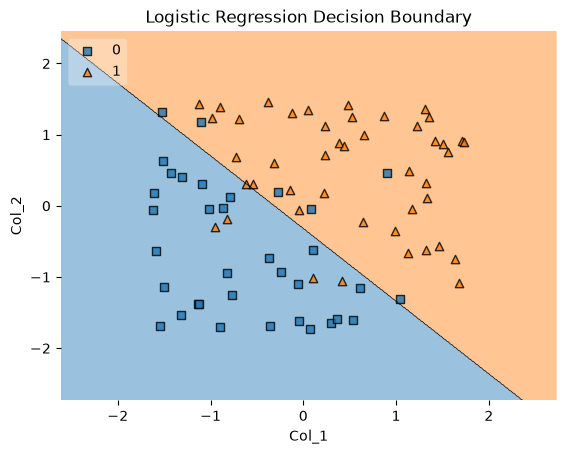

In [ ]:
from mlxtend.plotting import plot_decision_regions


X = predictions_df_train.iloc[:,:2].values
Y = predictions_df_train.loc[:,"Y"].values

# Plotting decision regions
plot_decision_regions(X, Y, clf=classifier, legend=2)

# Adding axes annotations
plt.xlabel('Col_1')
plt.ylabel('Col_2')
plt.title('Logistic Regression Decision Boundary')
plt.show()